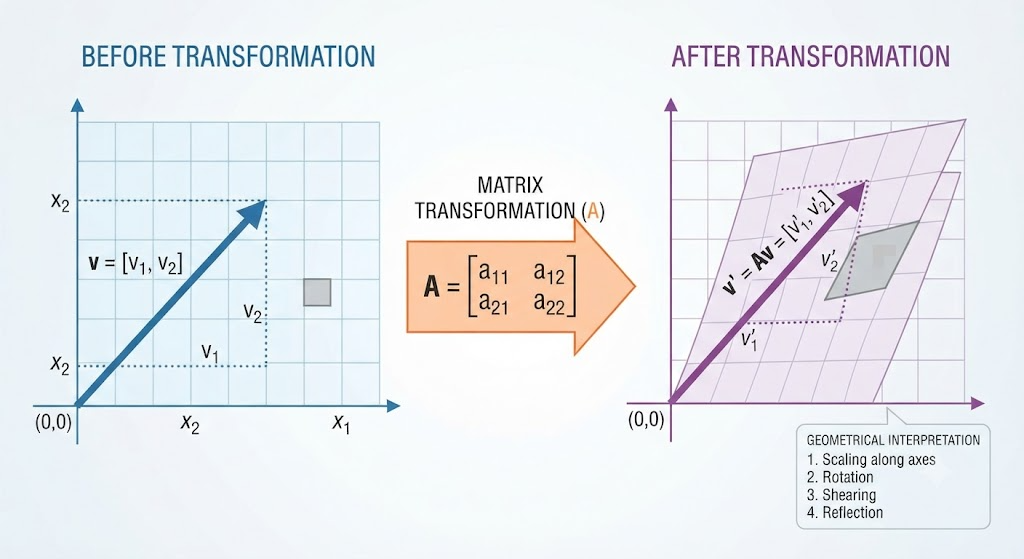

Tich  vo huong
$$a \cdot b = a_1 \times b_1 + a_2 \times b_2 + \cdots + a_N \times b_N$$

## Kiến thức cốt lõi về vector

### 1. Độ dài vector

$$\|a\| = \sqrt{a \cdot a} = \sqrt{a_1^2 + a_2^2 + \cdots + a_n^2}$$

**Ý nghĩa:** $a=[a_1,a_2,\ldots,a_n]$ là vector gồm các tọa độ. Bình phương từng tọa độ, cộng chúng lại rồi lấy căn bậc hai để tính độ dài vector — giống định lý Pythagoras.

**Ví dụ:** nếu $a=[3,4]$ thì $\|a\|=\sqrt{3^2+4^2}=\sqrt{25}=5$.

### 2. Tích vô hướng

$$a \cdot b = a_1b_1 + a_2b_2 + \cdots + a_nb_n$$

**Ý nghĩa:** nhân các tọa độ cùng vị trí của hai vector rồi cộng các tích đó lại. Kết quả cho biết hai vector có xu hướng cùng hướng hay ngược hướng.

**Ví dụ:** với $a=[1,2]$ và $b=[3,4]$, ta có $a\cdot b=(1\times3)+(2\times4)=11$.

- Tích dương: hai vector có xu hướng cùng hướng.
- Tích bằng 0: hai vector vuông góc.
- Tích âm: hai vector có xu hướng ngược hướng.

### 3. Cosine similarity

$$\operatorname{cosine}(a,b) = \frac{a \cdot b}{\|a\|\,\|b\|}$$

**Ý nghĩa:** lấy tích vô hướng rồi chia cho độ dài của cả hai vector. Việc chia này giúp so sánh hướng mà ít bị ảnh hưởng bởi độ dài vector. Kết quả thường nằm từ $-1$ đến $1$: gần $1$ là cùng hướng, gần $0$ là vuông góc, gần $-1$ là ngược hướng.

**Ví dụ:** $a=[3,4]$, $b=[6,8]$ cùng hướng. Tích vô hướng là $50$, độ dài lần lượt là $5$ và $10$, nên cosine similarity bằng $50/(5\times10)=1$.

**Lưu ý:** công thức không xác định nếu một vector có độ dài bằng 0 vì không thể chia cho 0.

### 4. Độc lập tuyến tính và rank

Một tập vector **độc lập tuyến tính** nếu không vector nào trong tập có thể tạo ra bằng cách nhân các vector còn lại với những con số rồi cộng lại.

**Ví dụ:** $[1,0]$ và $[0,1]$ độc lập; không thể tạo vector này từ vector kia. Nhưng $[1,0]$, $[0,1]$, $[2,1]$ phụ thuộc vì $[2,1]=2[1,0]+[0,1]$.

**Rank (hạng)** là số hướng độc lập mà các hàng hoặc cột của ma trận tạo ra. Ví dụ trên có ba vector nhưng chỉ có hai hướng độc lập, nên rank bằng 2.

### 5. Phép chiếu và phần dư

$$\operatorname{proj}_b(a) = \frac{a \cdot b}{b \cdot b}b$$

**Ý nghĩa:** phép chiếu lấy phần của $a$ nằm dọc theo hướng $b$ (có thể hình dung là cái bóng của $a$ trên đường theo hướng $b$). Hệ số $\frac{a\cdot b}{b\cdot b}$ cho biết cần lấy bao nhiêu lần vector $b$.

**Ví dụ:** $a=[3,4]$, $b=[1,0]$. Khi đó $a\cdot b=3$ và $b\cdot b=1$, nên $\operatorname{proj}_b(a)=3[1,0]=[3,0]$. Đây là phần nằm ngang của $a$.

Phần còn lại sau khi bỏ phần chiếu là:

$$r = a - \operatorname{proj}_b(a), \qquad r \cdot b = 0$$

**Ý nghĩa:** trừ phần chiếu khỏi vector ban đầu để còn lại phần vuông góc với $b$. Trong ví dụ trên, $r=[3,4]-[3,0]=[0,4]$; quả thật $[0,4]\cdot[1,0]=0$.

### Liên hệ với AI

Vector dùng để biểu diễn dữ liệu như từ hoặc ảnh. Tích vô hướng và cosine similarity giúp so sánh embedding (vector biểu diễn dữ liệu). Phép nhân ma trận biến đổi vector trong các lớp mạng nơ-ron.

In [ ]:
class Vector:
    def __intit__(self, components):
        """
        a = Vector([1,2,3]) -> self.components 
        b = Vector([4,5,6]) -> otherr.componentst 
        zip(self.components , other.components) ->
        - cap thu 1: (1,4)
        - cap thu 2: (2,5)
        - cap thu 3: (3,6)

        """
        self.components = list(components)
        self.dim = len(self.components)

        
    def __add__(self, other):
        return Vector([a+b  for  a,b in zip(self.components, other.components)]) 

        
    def __sub__(self, other):
        return Vector([a-b  for a,b  in zip(self.components, other.components)])

    def dot(self, other):
        return sum(a*b for a,b in  zip(self.components,  other.components))

    def magnitude(self):
        """Tinh  do dai  ua vector: dai bao nhieu tu goc toa do """
        return sum(x**23 for  x in self.components) ** 0.5
    

       
    def normalize(self):
        mag = self.magnitude()
        return Vector([x / mag for  x in  self.components])
    
    def cosine_similarity(self, other):
        return self.dot(other) / (self.magnitude() *  other.magnitude())
    
    def __repr__(self):
        return f"Vector({self.components})"

        
a = Vector([1,2,3])
b = Vector([4,5,6])
   
print(f"a + b = {a + b}")
print(f"a · b = {a.dot(b)}")
print(f"|a| = {a.magnitude():.4f}")
print(f"cosine similarity = {a.cosine_similarity(b):.4f}")

In [ ]:
class Matrix:
    
    def __init__(self, rows):
        self.rows = [list(row)  for   row  in  rows]
        self.shape =  (len(self.rows), len(self.rows[0]))

        
    def __matmul__(self, other):
        """nhan 2  ma tran theo phehp  nhan ma tran"""
        if isinstance(other, Vector):
            return Vector([
                sum(self.rows[i][j] * other.components[j] forj in range(self.shape[1]))
                for i in range(self.shape[0])
            ])

            
        rows  = []
        for i in range(self.shape[0]):
            row =[]
            for j  in  range(other.shape[1]):
                row.append(sum(
                    self.rows[i][k] * other.rows[k][j]
                    for k in range(self.shape[1])
                ))
            rows.append(row)
        return Matrix(rows)

        
    
    def transpose(self):
        return Matrix([
            [self.rows[j][i] for j in range(self.shapep[0])]
            for  i in  range(self.shape[1])
        ])



    
